<h1><b>A02 on Fitting and Alignment</h1>


### **Student Details**

| Field | Details |
| :--- | :--- |
| **Name** | D.M.G.H. Adikaram |
| **Index Number** | 230018T |
|**Github**| https://github.com/Gimadikaram/A02-on-Fitting-and-Alignment.git |

<h3><b> Question 1: Sunflower Detection Using Laplacian of Gaussian</h3></b>

The objective is to detect circular sunflower blobs at different scales.

The image is converted to grayscale, and the scale-normalized Laplacian
of Gaussian (LoG) is calculated for multiple values of σ:

R(x, y, σ) = σ² ∇²(Gσ * I)(x, y)

Dark blobs surrounded by brighter regions produce positive LoG responses.
Therefore, local maxima are detected across both spatial coordinates and scale.

For an ideal uniform circular blob, its radius is approximately:

r = √2 σ


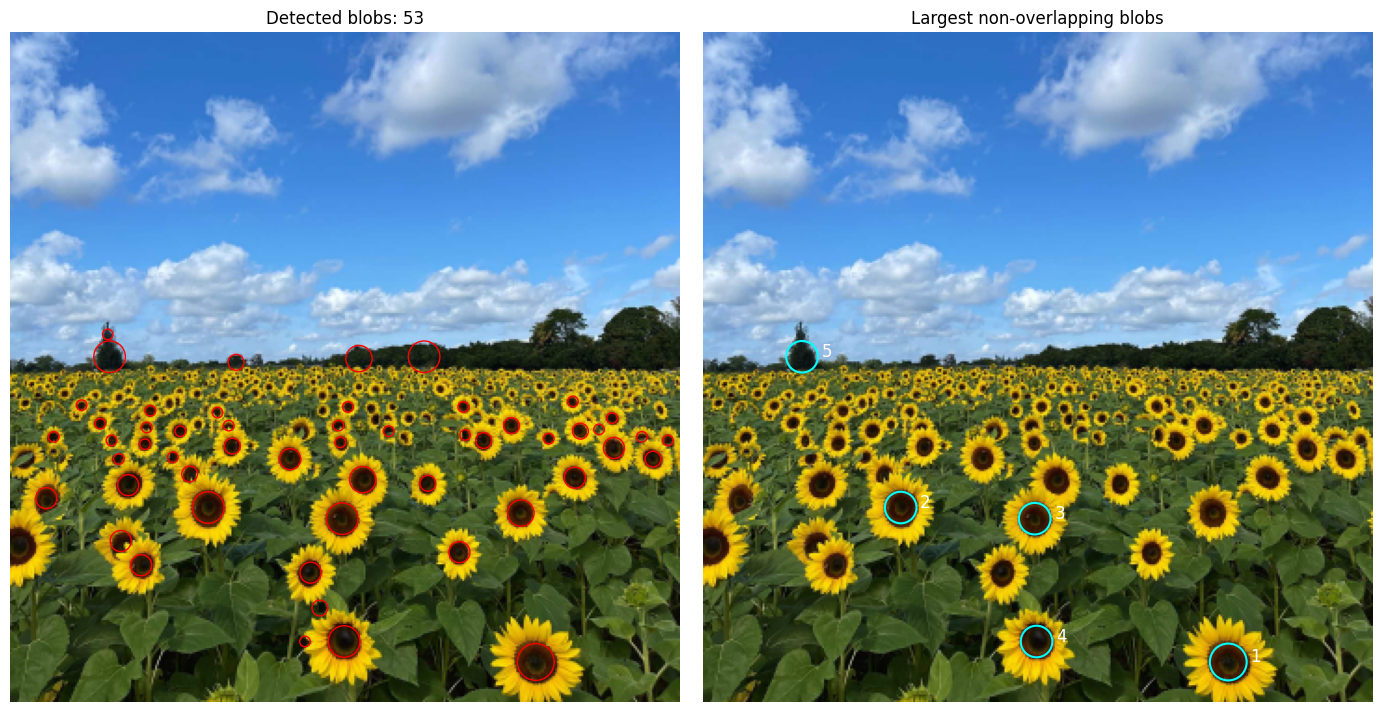

Sigma range: 1.0–10.0 pixels
Response threshold: 0.25
1: centre=(282, 338), radius=9.90 pixels, sigma=7.0
2: centre=(106, 255), radius=8.49 pixels, sigma=6.0
3: centre=(178, 261), radius=8.49 pixels, sigma=6.0
4: centre=(179, 327), radius=8.49 pixels, sigma=6.0
5: centre=(53, 174), radius=8.49 pixels, sigma=6.0


In [5]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

image_path = "C:/Users/ASUS/Downloads/CV ASSIGNMENT/A02-on-Fitting-and-Alignment/a2images/the_berry_farms_sunflower_field.jpeg"

im = cv.imread(image_path, cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError(image_path)

rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
h, w = gray.shape

# Scale-normalized LoG
sigmas = np.linspace(1, 10, 10)
threshold = 0.25
scale_space = np.empty((h, w, len(sigmas)), dtype=np.float32)

for i, sigma in enumerate(sigmas):
    half_width = int(np.ceil(3 * sigma))
    coordinates = np.arange(-half_width, half_width + 1)
    X, Y = np.meshgrid(coordinates, coordinates)
    r_squared = X**2 + Y**2

    kernel = (
        1 / (np.pi * sigma**2)
        * (r_squared / (2 * sigma**2) - 1)
        * np.exp(-r_squared / (2 * sigma**2))
    )
    kernel -= kernel.mean()

    scale_space[:, :, i] = cv.filter2D(
        gray, cv.CV_32F, kernel, borderType=cv.BORDER_REFLECT101
    )

# Local maxima across position and scale
mask = (
    (scale_space == maximum_filter(scale_space, size=(3, 3, 3)))
    & (scale_space > threshold)
)
mask[:, :, 0] = False
mask[:, :, -1] = False

for i, sigma in enumerate(sigmas):
    m = int(np.ceil(np.sqrt(2) * sigma))
    mask[:m, :, i] = mask[-m:, :, i] = False
    mask[:, :m, i] = mask[:, -m:, i] = False

ys, xs, ss = np.where(mask)
radii = np.sqrt(2) * sigmas[ss]
responses = scale_space[ys, xs, ss]

# Five largest non-overlapping circles
chosen = []

for idx in np.lexsort((-responses, -radii)):
    x, y, r = xs[idx], ys[idx], radii[idx]

    if all(
        np.hypot(x - cx, y - cy) > r + cr
        for cx, cy, cr, _ in chosen
    ):
        chosen.append((x, y, r, sigmas[ss[idx]]))

    if len(chosen) == 5:
        break

# Display results
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax in axes:
    ax.imshow(rgb)
    ax.axis("off")

for x, y, r in zip(xs, ys, radii):
    axes[0].add_patch(
        plt.Circle((x, y), r, color="red", fill=False, linewidth=1)
    )

for number, (x, y, r, sigma) in enumerate(chosen, 1):
    axes[1].add_patch(
        plt.Circle((x, y), r, color="cyan", fill=False, linewidth=1.5)
    )
    axes[1].text(x + r + 2, y, str(number), color="white", fontsize=12)

axes[0].set_title(f"Detected blobs: {len(xs)}")
axes[1].set_title("Largest non-overlapping blobs")
plt.tight_layout()
plt.show()

# Report parameters in reduced-image pixels
print(f"Sigma range: {sigmas.min():.1f}–{sigmas.max():.1f} pixels")
print(f"Response threshold: {threshold}")

for number, (x, y, r, sigma) in enumerate(chosen, 1):
    print(
        f"{number}: centre=({x}, {y}), "
        f"radius={r:.2f} pixels, sigma={sigma:.1f}"
    )

### Blob Detection Using Scale-Normalized LoG

The image was loaded at one-quarter resolution, converted to grayscale, and normalized to $[0,1]$. Scale-normalized Laplacian of Gaussian (LoG) filters were applied at ten scales, $\sigma = 1,2,\ldots,10$:

$$
R(x,y,\sigma)=\sigma^2\nabla^2(G_\sigma * I)
$$

The factor $\sigma^2$ makes responses comparable across scales. Positive responses identify dark sunflower centres surrounded by brighter petals.

Blob candidates were detected as local maxima within a $3 \times 3 \times 3$ neighbourhood across position and scale. A threshold of **0.25** suppressed weak responses. This was a chosen parameter, not an optimized value. Endpoint scales and circles extending beyond the image were excluded.

Each blob was assigned a centre $(x,y)$ and an approximate radius:

$$
r=\sqrt{2}\sigma
$$

All candidates were displayed, and the **five largest non-overlapping circles** were selected for reporting. Coordinates and radii refer to the reduced image.

The circles represent the **dark sunflower centres**, rather than the full petal outlines. Some false detections may remain because LoG also responds to other dark regions.

<h3><b>Question 2: Robust Line and Circle Fitting Using RANSAC</h3></b>

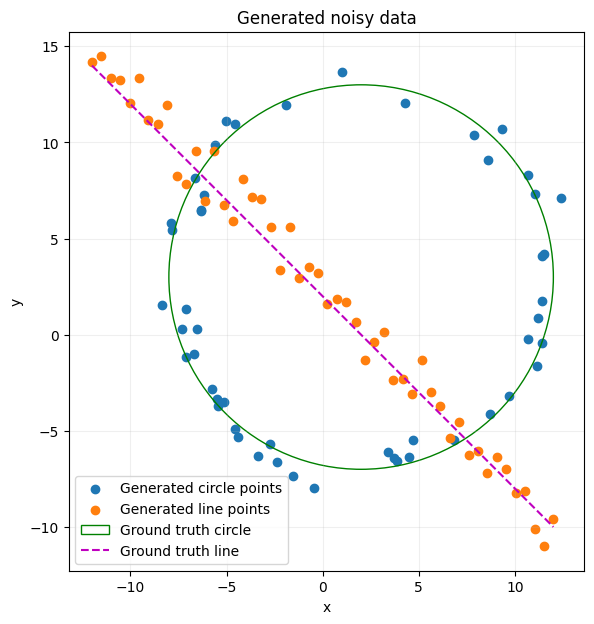

Total points: 100


In [18]:
from scipy.optimize import minimize

np.random.seed(0)
rng = np.random.default_rng(1)

N = 100
half_n = N // 2

# Circle points
r_gt = 10
center_gt = np.array([2.0, 3.0])

t = np.random.uniform(0, 2 * np.pi, half_n)
noise = (r_gt / 16) * np.random.randn(half_n)

X_circ = center_gt + np.column_stack((
    (r_gt + noise) * np.cos(t),
    (r_gt + noise) * np.sin(t)
))

# Line points
x = np.linspace(-12, 12, half_n)
y = -x + 2 + np.random.randn(half_n)
X_line = np.column_stack((x, y))

X = np.vstack((X_circ, X_line))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(*X_circ.T, label="Generated circle points")
ax.scatter(*X_line.T, label="Generated line points")

ax.add_patch(
    plt.Circle(center_gt, r_gt, fill=False,
               color="green", label="Ground truth circle")
)
ax.plot(x, -x + 2, "m--", label="Ground truth line")

ax.set_aspect("equal")
ax.set_title("Generated noisy data")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

print(f"Total points: {len(X)}")

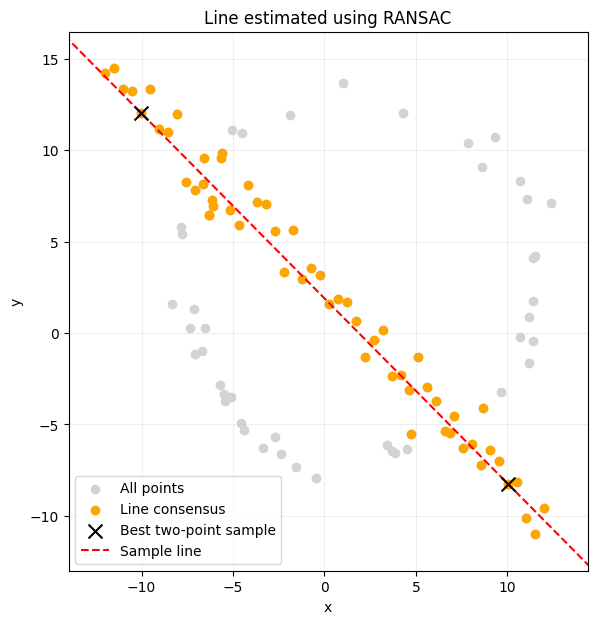

Sample line: 0.7109x + 0.7033y = 1.3370
Consensus size: 58


In [19]:
def fit_line(points):
    center = points.mean(axis=0)
    _, _, vt = np.linalg.svd(points - center, full_matrices=False)

    normal = vt[-1]
    normal /= np.linalg.norm(normal)
    d = normal @ center

    if d < 0:
        normal = -normal
        d = -d

    return np.array([normal[0], normal[1], d])


def line_error(model, points):
    a, b, d = model
    return np.abs(points @ np.array([a, b]) - d)


# Handles vertical lines as well.
def draw_line(ax, model, color, style, label):
    a, b, d = model
    anchor = d * np.array([a, b])
    direction = np.array([-b, a])

    extent = 3 * np.max(np.abs(X)) + abs(d)
    points = anchor + np.array([-extent, extent])[:, None] * direction

    ax.plot(*points.T, color=color, linestyle=style, label=label)


def format_axes(ax, title):
    ax.set_xlim(X[:, 0].min() - 2, X[:, 0].max() + 2)
    ax.set_ylim(X[:, 1].min() - 2, X[:, 1].max() + 2)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)
    ax.grid(alpha=0.2)


line_threshold = 2.0
iterations = 1000
min_line_consensus = 35

best_score = (-1, -np.inf)
line_sample_model = None

for _ in range(iterations):
    sample = X[rng.choice(len(X), 2, replace=False)]

    if np.linalg.norm(sample[0] - sample[1]) < 1e-10:
        continue

    model = fit_line(sample)
    errors = line_error(model, X)
    mask = errors < line_threshold

    score = (int(mask.sum()), -float(np.sum(errors[mask]**2)))

    if score > best_score:
        best_score = score
        line_sample_model = model.copy()
        line_sample_points = sample.copy()
        line_sample_mask = mask.copy()

if line_sample_model is None or best_score[0] < min_line_consensus:
    raise RuntimeError("No line met the minimum consensus requirement.")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(*X.T, color="lightgray", label="All points")
ax.scatter(*X[line_sample_mask].T, color="orange", label="Line consensus")
ax.scatter(
    *line_sample_points.T, color="black", marker="x", s=100,
    label="Best two-point sample", zorder=5
)

draw_line(ax, line_sample_model, "red", "--", "Sample line")
format_axes(ax, "Line estimated using RANSAC")
ax.legend()
plt.show()

a, b, d = line_sample_model
print(f"Sample line: {a:.4f}x + {b:.4f}y = {d:.4f}")
print(f"Consensus size: {line_sample_mask.sum()}")

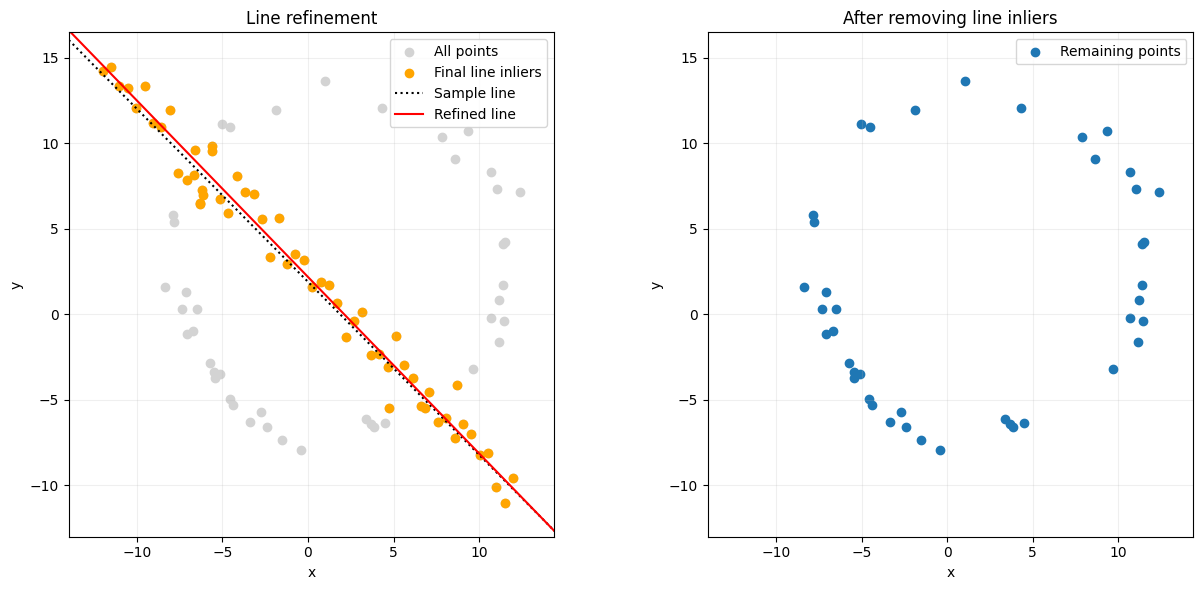

Refined line: 0.7179x + 0.6962y = 1.5209
Normal magnitude: 1.0000
Final line inliers: 58
Remaining points: 42


In [20]:
# Total least-squares fit using the winning consensus.
line_best = fit_line(X[line_sample_mask])

# Reclassify points using the refined line.
line_mask = line_error(line_best, X) < line_threshold

if line_mask.sum() < min_line_consensus:
    raise RuntimeError("Refined line has insufficient consensus.")

remaining = X[~line_mask]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].scatter(*X.T, color="lightgray", label="All points")
axes[0].scatter(*X[line_mask].T, color="orange", label="Final line inliers")

draw_line(axes[0], line_sample_model, "black", ":", "Sample line")
draw_line(axes[0], line_best, "red", "-", "Refined line")

axes[1].scatter(*remaining.T, color="tab:blue", label="Remaining points")

format_axes(axes[0], "Line refinement")
format_axes(axes[1], "After removing line inliers")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

a, b, d = line_best
print(f"Refined line: {a:.4f}x + {b:.4f}y = {d:.4f}")
print(f"Normal magnitude: {np.hypot(a, b):.4f}")
print(f"Final line inliers: {line_mask.sum()}")
print(f"Remaining points: {len(remaining)}")

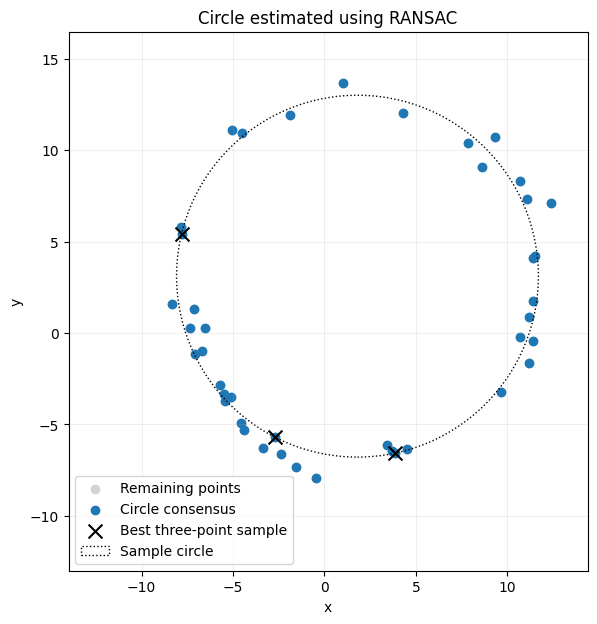

Sample circle centre: (1.809, 3.113)
Sample radius: 9.898
Consensus size: 42


In [21]:
def fit_circle_sample(points):
    p1, p2, p3 = points

    A = 2 * np.vstack((p2 - p1, p3 - p1))
    B = np.array([
        p2 @ p2 - p1 @ p1,
        p3 @ p3 - p1 @ p1
    ])

    if np.linalg.cond(A) > 1e10:
        raise ValueError("Collinear or nearly collinear points.")

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1 - center)

    return np.array([center[0], center[1], radius])


def circle_error(model, points):
    return np.linalg.norm(points - model[:2], axis=1) - model[2]


circle_threshold = 1.5
min_circle_consensus = 25

best_score = (-1, -np.inf)
circle_sample_model = None

if len(remaining) < 3:
    raise RuntimeError("Insufficient remaining points.")

for _ in range(iterations):
    sample = remaining[rng.choice(len(remaining), 3, replace=False)]

    try:
        model = fit_circle_sample(sample)
    except (ValueError, np.linalg.LinAlgError):
        continue

    errors = np.abs(circle_error(model, remaining))
    mask = errors < circle_threshold

    score = (int(mask.sum()), -float(np.sum(errors[mask]**2)))

    if score > best_score:
        best_score = score
        circle_sample_model = model.copy()
        circle_sample_points = sample.copy()
        circle_sample_mask = mask.copy()

if circle_sample_model is None or best_score[0] < min_circle_consensus:
    raise RuntimeError("No circle met the minimum consensus requirement.")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(*remaining.T, color="lightgray", label="Remaining points")
ax.scatter(
    *remaining[circle_sample_mask].T,
    color="tab:blue", label="Circle consensus"
)
ax.scatter(
    *circle_sample_points.T, color="black", marker="x", s=100,
    label="Best three-point sample", zorder=5
)

ax.add_patch(
    plt.Circle(
        circle_sample_model[:2], circle_sample_model[2],
        fill=False, color="black", linestyle=":",
        label="Sample circle"
    )
)

format_axes(ax, "Circle estimated using RANSAC")
ax.legend()
plt.show()

cx, cy, radius = circle_sample_model
print(f"Sample circle centre: ({cx:.3f}, {cy:.3f})")
print(f"Sample radius: {radius:.3f}")
print(f"Consensus size: {circle_sample_mask.sum()}")

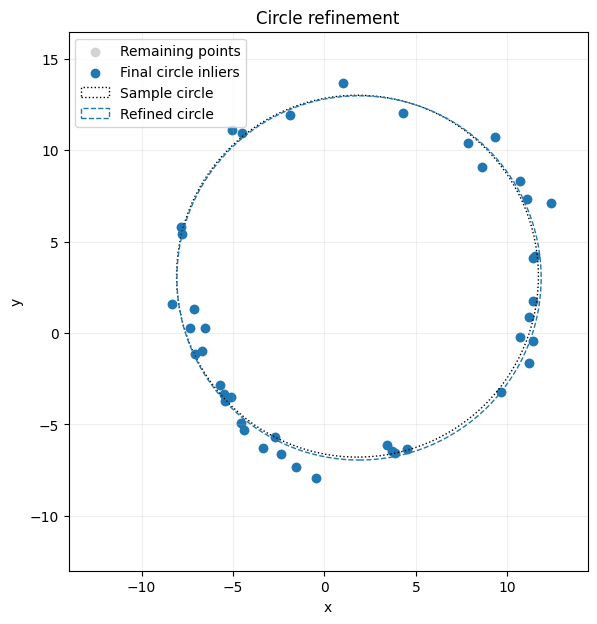

Refined centre: (1.893, 3.018)
Refined radius: 9.964
Final circle inliers: 42
Consensus radial RMSE: 0.5723 → 0.5615


In [22]:
result = minimize(
    lambda model: np.sum(
        circle_error(model, remaining[circle_sample_mask])**2
    ),
    x0=circle_sample_model,
    method="L-BFGS-B",
    bounds=[(None, None), (None, None), (1e-6, None)]
)

if not result.success:
    raise RuntimeError(f"Circle refinement failed: {result.message}")

circle_best = result.x

circle_mask = (
    np.abs(circle_error(circle_best, remaining)) < circle_threshold
)

if circle_mask.sum() < min_circle_consensus:
    raise RuntimeError("Refined circle has insufficient consensus.")

# Compare errors on the same consensus used for refinement.
fit_points = remaining[circle_sample_mask]
rmse_before = np.sqrt(np.mean(circle_error(circle_sample_model, fit_points)**2))
rmse_after = np.sqrt(np.mean(circle_error(circle_best, fit_points)**2))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(*remaining.T, color="lightgray", label="Remaining points")
ax.scatter(
    *remaining[circle_mask].T,
    color="tab:blue", label="Final circle inliers"
)

for model, color, style, label in [
    (circle_sample_model, "black", ":", "Sample circle"),
    (circle_best, "tab:blue", "--", "Refined circle")
]:
    ax.add_patch(
        plt.Circle(
            model[:2], model[2], fill=False,
            color=color, linestyle=style, label=label
        )
    )

format_axes(ax, "Circle refinement")
ax.legend()
plt.show()

cx, cy, radius = circle_best
print(f"Refined centre: ({cx:.3f}, {cy:.3f})")
print(f"Refined radius: {radius:.3f}")
print(f"Final circle inliers: {circle_mask.sum()}")
print(f"Consensus radial RMSE: {rmse_before:.4f} → {rmse_after:.4f}")

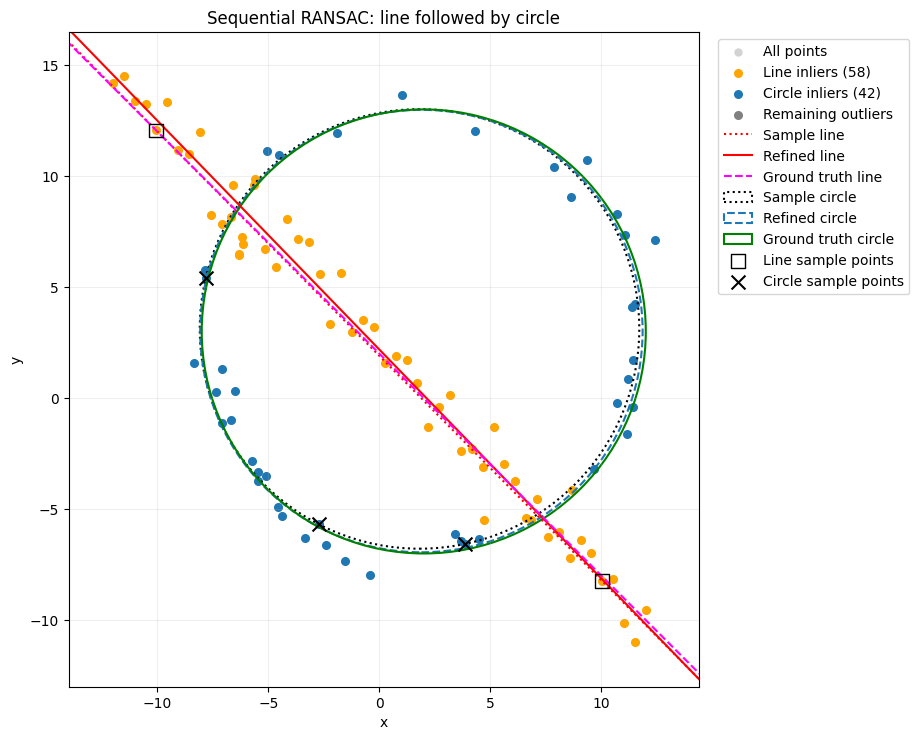

In [23]:
fig, ax = plt.subplots(figsize=(9, 9))

ax.scatter(*X.T, color="lightgray", s=25, label="All points")
ax.scatter(
    *X[line_mask].T, color="orange", s=30,
    label=f"Line inliers ({line_mask.sum()})"
)
ax.scatter(
    *remaining[circle_mask].T, color="tab:blue", s=30,
    label=f"Circle inliers ({circle_mask.sum()})"
)
ax.scatter(
    *remaining[~circle_mask].T, color="gray", s=30,
    label="Remaining outliers"
)

draw_line(ax, line_sample_model, "red", ":", "Sample line")
draw_line(ax, line_best, "red", "-", "Refined line")
draw_line(
    ax, np.array([1, 1, 2]) / np.sqrt(2),
    "magenta", "--", "Ground truth line"
)

for model, color, style, label in [
    (circle_sample_model, "black", ":", "Sample circle"),
    (circle_best, "tab:blue", "--", "Refined circle"),
    (np.array([2, 3, 10]), "green", "-", "Ground truth circle")
]:
    ax.add_patch(
        plt.Circle(
            model[:2], model[2], fill=False,
            edgecolor=color, linestyle=style,
            linewidth=1.5, label=label
        )
    )

ax.scatter(
    *line_sample_points.T,
    marker="s", s=100, facecolors="none", edgecolors="black",
    label="Line sample points", zorder=5
)
ax.scatter(
    *circle_sample_points.T,
    marker="x", s=100, color="black",
    label="Circle sample points", zorder=5
)

format_axes(ax, "Sequential RANSAC: line followed by circle")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

### <b>What happens if the circle is fitted first?</b>

Fitting the circle first can succeed, but it may select an incorrect,
very large circle whose arc approximates the line. Such a circle can
collect many line points as inliers.

Removing the line first reduces this ambiguity. However, some circle
points near the line–circle intersections may also be removed, leaving
fewer points for circle estimation.

<h3><b> Question 3: Image Superimposition Using Homography</h3></b>
